# Measuring cuneiform tablets with the Shaping History VAE

This notebook accompanies Gordin, Kapon Epshtain, Alper and Fire, *Shaping History* (PNAS, forthcoming).
It shows how to read the twelve numbers that our variational autoencoder (VAE) gives to every photographed tablet in CDLI,
and how to turn them into measurements that a diplomatist can use: **proportion**, **relative thickness** and, less
reliably, **the squareness of the corners**.

**What you need:** Python 3 with `pandas`, `numpy`, `matplotlib`, `scikit-learn` and `requests`. Nothing is trained here;
the notebook only reads published tables. Run the cells from top to bottom.

**Data.** The VAE vectors and the black-and-white silhouettes are published on Zenodo
([10.5281/zenodo.12787746](https://doi.org/10.5281/zenodo.12787746), CC BY 4.0); the trained model is at
[10.5281/zenodo.11668220](https://doi.org/10.5281/zenodo.11668220). The measurements of each silhouette, and the
guide to the twelve numbers, are in this repository under `data/vae_measure/`.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, io, requests, os
ZEN='https://zenodo.org/records/12787746/files/'
HERE='data/vae_measure/'          # tables released with the article
def zenodo_csv(name):
    if not os.path.exists(name):
        open(name,'wb').write(requests.get(ZEN+name+'?download=1',timeout=300).content)
    return pd.read_csv(name)
vae=pd.concat([zenodo_csv(f'vae_encoding_df_April16_w_class_{s}.csv') for s in ['train','val','test']]).drop_duplicates('CDLI_id')
X=[f'X{i}' for i in range(1,13)]
print(len(vae),'tablets with a VAE vector'); vae[['CDLI_id','Period_Name','Genre_Name']+X].head()

92876 tablets with a VAE vector


,CDLI_id,Period_Name,Genre_Name,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11,X12
0,100002,Ur III,Administrative,0.308070,0.582938,-0.226466,-1.790538,2.199212,1.082523,0.060125,-1.704444,-0.449629,-1.541325,-1.226439,3.015560
1,100004,Ur III,Administrative,0.613563,0.334441,-0.198854,-1.407669,1.295915,2.089747,0.126103,0.399121,-0.608196,-1.212519,-0.522786,3.258323
2,100005,Ur III,Administrative,0.632997,-1.426166,-0.374072,-1.822843,1.783719,1.104585,-0.127399,0.059052,-0.834835,-1.556640,-0.301518,2.501972
3,100014,Ur III,Administrative,-1.705593,-3.175075,-1.006676,0.495734,0.482745,-0.531953,-0.731508,0.012689,-2.168423,0.666772,-0.427666,3.518940
4,100023,Ur III,Administrative,-0.093872,-3.950407,-0.815141,-0.661895,0.123871,-1.128830,0.431454,2.055738,0.069460,-0.291593,-1.568285,2.037653


## 1. What the twelve numbers record

Each tablet photograph in CDLI shows six views in a cross: top edge, obverse with the two side edges, bottom edge and
reverse. The VAE reduced the black-and-white silhouette of that cross to twelve numbers, **X1 to X12**. It was not told
what to look for, although it was also trained to recognise the period of the tablet, so its numbers favour features
that differ between periods.

To name each number, we measured every silhouette directly (proportion of the obverse, thickness of the edges against the
width, how square the corners are, and so on) and asked which measurement each number follows most closely.

In [2]:
guide=pd.read_csv(HERE+'vae_dimension_guide.csv')
guide[['dim','reads','closest_name','rho','strength']].rename(columns={'dim':'number','reads':'how to read it',
      'closest_name':'closest physical measurement','rho':'correlation'})

,number,how to read it,closest physical measurement,correlation,strength
0,X1,higher = taller,proportion (height ÷ width of the obverse),0.27,weak
1,X2,higher = wider,proportion (height ÷ width of the obverse),-0.79,clear
2,X3,higher = thinner at the sides,thickness at the sides ÷ width,-0.64,clear
3,X4,higher = rounder corners,squareness of the corners (obverse),-0.36,weak
4,X5,higher = rounder,roundness of the outline,0.32,weak
5,X6,higher = more rectangular,how rectangular the obverse is,0.35,weak
6,X7,higher = taller,proportion (height ÷ width of the obverse),0.40,weak
7,X8,higher = thinner at the ends,thickness at top and bottom ÷ width,-0.28,weak
8,X9,higher = thicker at the ends,thickness at top and bottom ÷ width,0.41,partial
9,X10,higher = taller,proportion (height ÷ width of the obverse),0.50,partial


The figure shows, for each number, three real tablets: one low, one in the middle and one high on that number, each
chosen to be typical on the other eleven. The numbers marked *clear* can be read on their own; the others work only
together with the rest.

![The twelve VAE numbers](data/vae_measure/fig_vae_dimension_guide.png)

## 2. From twelve numbers to measurements

A single number is a blunt tool. Combined, the twelve numbers predict some measurements well. The table gives, for each
measurement, the share of its variation across the corpus that the twelve numbers recover (R², from 0 to 1, by five-fold
cross-validation).

In [3]:
rec=pd.read_csv(HERE+'vae_feature_recovery_all.csv'); rec

,feature,description,R2_well_preserved,R2_all,n_well_preserved,n_all,reliability
0,hw,proportion (height ÷ width of the obverse),0.82,0.72,47714,76049,reliable
1,thick_side,thickness at the sides ÷ width,0.71,0.61,47096,74265,reliable
2,thick_end,thickness at top and bottom ÷ width,0.70,0.59,46297,73131,reliable
3,rect,how rectangular the obverse is,0.51,0.54,47714,76049,partial
4,corner_fill,squareness of the corners (obverse),0.46,0.45,47714,76049,partial
5,rev_corner_fill,squareness of the corners (reverse),0.44,0.44,47714,76049,partial
6,side_bulge,bulge of the long sides,0.39,0.33,47714,76049,not recovered
7,end_bulge,bulge of the short sides,0.37,0.30,47714,76049,not recovered
8,circ,roundness of the outline,0.22,0.14,47714,76049,not recovered
9,taper,taper (top width ÷ bottom width),0.16,0.15,47714,76049,not recovered


**How to use this.** Proportion and relative thickness can be read from the VAE for any tablet. Rectangularity and corner
shape can be used to compare groups of tablets (an archive, a city, a museum collection), not to describe one tablet.
Roundness and breaks cannot be read from the VAE.

Note that the photographs carry no scale: all measurements here are ratios. Size in millimetres comes only from the CDLI
catalogue.

In [4]:
M=pd.read_csv(HERE+'vae_measured_and_predicted.csv').merge(
    vae[['CDLI_id','Period_Name','Genre_Name']+X].rename(columns={'CDLI_id':'id'}),on='id')
print(len(M),'tablets;',int(M.measured.sum()),'measured on the silhouette;',int(M.well_preserved.sum()),'well preserved'); M.head()

92876 tablets; 76049 measured on the silhouette; 47714 well preserved


,id,well_preserved,measured,hw_pred,thick_side_pred,thick_end_pred,corner_fill_pred,rev_corner_fill_pred,rect_pred,hw,...,X3,X4,X5,X6,X7,X8,X9,X10,X11,X12
0,100002,False,True,0.993,0.455,0.437,0.682,0.649,0.947,0.713,...,-0.226466,-1.790538,2.199212,1.082523,0.060125,-1.704444,-0.449629,-1.541325,-1.226439,3.015560
1,100004,False,True,1.054,0.397,0.371,0.580,0.555,0.931,1.035,...,-0.198854,-1.407669,1.295915,2.089747,0.126103,0.399121,-0.608196,-1.212519,-0.522786,3.258323
2,100005,True,True,1.172,0.424,0.398,0.514,0.491,0.905,1.204,...,-0.374072,-1.822843,1.783719,1.104585,-0.127399,0.059052,-0.834835,-1.556640,-0.301518,2.501972
3,100014,True,True,1.528,0.350,0.358,0.485,0.452,0.910,1.447,...,-1.006676,0.495734,0.482745,-0.531953,-0.731508,0.012689,-2.168423,0.666772,-0.427666,3.518940
4,100023,True,True,1.516,0.426,0.423,0.426,0.392,0.889,1.785,...,-0.815141,-0.661895,0.123871,-1.128830,0.431454,2.055738,0.069460,-0.291593,-1.568285,2.037653


## 3. Look up one tablet

Give a CDLI number (P-number). The bars show where the tablet stands on each of the twelve numbers against the whole corpus
(percentile); the table gives its measurements, as measured on the silhouette and as read from the VAE.

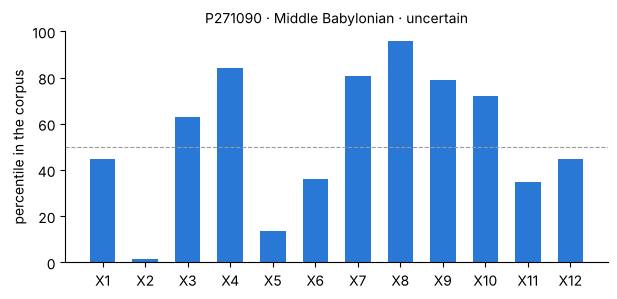

https://cdli.earth/P271090


,measured on the silhouette,read from the VAE
proportion (h ÷ w),2.18,1.52
thickness at the sides ÷ width,0.22,0.33
thickness at the ends ÷ width,0.18,0.34
rectangularity,0.92,0.87
corner squareness,0.30,0.32


In [5]:
def tablet(p):
    pid=int(str(p).lstrip('Pp')); r=M[M.id==pid]
    if r.empty: return print('No VAE vector for this tablet.')
    r=r.iloc[0]; pct=[(M[x]<r[x]).mean()*100 for x in X]
    fig,ax=plt.subplots(figsize=(7,3)); ax.bar(X,pct,color='#2a78d6',width=.6); ax.axhline(50,color='#999',lw=.8,ls='--')
    ax.set_ylim(0,100); ax.set_ylabel('percentile in the corpus'); ax.set_title(f'P{pid:06d} · {r.Period_Name} · {r.Genre_Name}',fontsize=10)
    for s in ['top','right']: ax.spines[s].set_visible(False)
    plt.show()
    feats=['hw','thick_side','thick_end','rect','corner_fill']
    print(f'https://cdli.earth/P{pid:06d}')
    return pd.DataFrame({'measured on the silhouette':[r[f] if r.measured else np.nan for f in feats],'read from the VAE':[r[f+'_pred'] for f in feats]},
                        index=['proportion (h ÷ w)','thickness at the sides ÷ width','thickness at the ends ÷ width',
                               'rectangularity','corner squareness']).round(2)
tablet('P271090')   # EA 287, a letter of Abdi-Heba of Jerusalem

## 4. Compare groups

The same table can compare any groups that CDLI records. Here: the relative thickness of tablets by period, as read from the
VAE. Replace the periods, or filter by genre, to ask your own question.

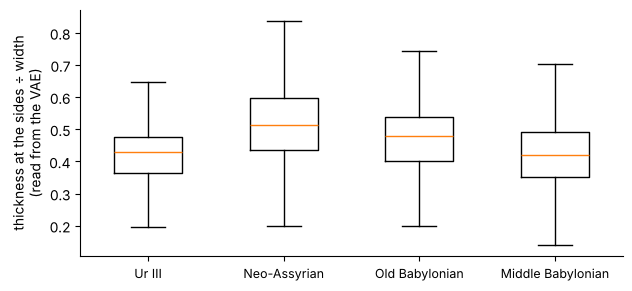

In [6]:
periods=['Ur III (ca. 2100-2000 BC)','Old Babylonian (ca. 1900-1600 BC)','Neo-Assyrian (ca. 911-612 BC)','Neo-Babylonian (ca. 626-539 BC)']
periods=[p for p in periods if p in set(M.Period_Name)] or M.Period_Name.value_counts().index[:4].tolist()
d=M[M.Period_Name.isin(periods)]
fig,ax=plt.subplots(figsize=(7,3.2))
ax.boxplot([d[d.Period_Name==p].thick_side_pred.dropna() for p in periods],showfliers=False,widths=.5)
ax.set_xticks(range(1,len(periods)+1)); ax.set_xticklabels([p.split(' (')[0] for p in periods],fontsize=9)
ax.set_ylabel('thickness at the sides ÷ width\n(read from the VAE)')
for s in ['top','right']: ax.spines[s].set_visible(False)
plt.show()

## 5. Caveats

* The silhouettes come from CDLI photographs of different museums. Photographic practice differs between museums, and
  in the article we control for the holding museum. Do the same when you compare groups.
* Broken tablets have broken outlines. Use the `solidity` column (1 = intact outline) to keep well-preserved tablets.
* Values read from the VAE are pulled toward the average: an unusually tall tablet will be read as less tall than it is
  (EA 287 above: 2.18 measured, 1.52 read). Use them to compare groups, and use the measured values when a single tablet
  matters. Measured values exist for the 76,049 tablets whose photograph shows six clean views; the VAE reading exists for
  all 92,876.
* The VAE was trained with the period of each tablet as a second target, so its numbers are tuned to what distinguishes
  periods.
* Cite the article and the Zenodo records when you use these data.